# Tree-model comparison

Compare Random Forest, XGBoost, and LightGBM with the existing dummy and logistic-regression baselines. This notebook uses only the cleaned training data. The held-out 2019 Imelda test data is not loaded or used.

## 1. Load cleaned training data and helpers

All validation and feature preparation use the shared project functions.

In [1]:
import sys
from pathlib import Path
from time import perf_counter

project_root = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "src" / "config.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the FloodSense project root from the notebook working directory.")
sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.pipeline import Pipeline

from src.data import load_clean
from src.evaluate import (
    RESULTS_PATH,
    cross_validate,
    plot_confusion_matrix,
    plot_roc_pr,
    save_results,
)
from src.features import (
    area_group_splits,
    build_preprocessor,
    get_xy,
    leave_one_storm_out_splits,
)
from src.models import MODEL_REGISTRY

df = load_clean()
print(f"Loaded {len(df):,} cleaned training rows; held-out 2019 test data was not used.")

Cleaned training data shape: (66514, 14)
Missing values by column:
year                   0
storm_name             0
storm_date             0
lat                    0
lon                    0
weight                 0
elevation_m            0
slope_degrees          0
distance_to_bayou_m    0
paved_pct              0
land_cover_type        0
rainfall_inches        0
flooded                0
grid_id                0
Loaded 66,514 cleaned training rows; held-out 2019 test data was not used.


**My observations:** The cleaned training set has 66,514 rows and no missing values in the listed columns. The held-out 2019 Imelda test data was not used.

## 2. Create geographic and storm validation splits

Area-group validation holds out geographic grid cells. Leave-one-storm-out validation holds out one storm at a time; it may still include locations represented in training.

In [2]:
area_splits = list(area_group_splits(df, n_splits=5))
storm_splits = list(leave_one_storm_out_splits(df, drop_overlap_areas=False))
print(f"Area-group folds: {len(area_splits)}; leave-one-storm-out folds: {len(storm_splits)}")

Area-group folds: 5; leave-one-storm-out folds: 3


**My observations:** The five area-group folds test performance in held-out places. The three storm folds test a held-out storm, but locations can overlap with training data.

## 3. Evaluate the three tree models

Each fold gets its own fitted preprocessing pipeline. The fixed model settings are defined in `src/models.py`; this comparison does not tune them. Results and out-of-fold predictions are saved for both validation designs.

In [3]:
tree_model_names = ("random_forest", "xgboost", "lightgbm")
split_sets = (
    ("area_group", area_splits),
    ("leave_one_storm_out", storm_splits),
)
evaluation_results = {}
model_seconds = {}

for model_name in tree_model_names:
    started = perf_counter()
    for split_name, splits in split_sets:
        summary_df, oof_df = cross_validate(
            MODEL_REGISTRY[model_name],
            df,
            splits,
            name=model_name,
            split_name=split_name,
        )
        save_results(summary_df, oof_df, model_name, split_name)
        evaluation_results[(model_name, split_name)] = (summary_df, oof_df)
    model_seconds[model_name] = perf_counter() - started
    print(f"{model_name} total validation time: {model_seconds[model_name]:.1f} seconds")

print("All tree-model validation runs finished.")

Saved results to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\results.csv
Saved OOF predictions to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\oof_random_forest_area_group.csv


Saved results to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\results.csv
Saved OOF predictions to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\oof_random_forest_leave_one_storm_out.csv
random_forest total validation time: 32.6 seconds


Saved results to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\results.csv
Saved OOF predictions to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\oof_xgboost_area_group.csv


Saved results to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\results.csv
Saved OOF predictions to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\oof_xgboost_leave_one_storm_out.csv
xgboost total validation time: 7.3 seconds


Saved results to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\results.csv
Saved OOF predictions to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\oof_lightgbm_area_group.csv


Saved results to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\results.csv
Saved OOF predictions to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\oof_lightgbm_leave_one_storm_out.csv
lightgbm total validation time: 6.6 seconds
All tree-model validation runs finished.


**My observations:** All three tree models ran with the fixed settings and seed 42. The full cross-validation runs took 32.6 seconds for Random Forest, 7.3 for XGBoost, and 6.6 for LightGBM on this computer.

## 4. Compare all five models

This table includes the existing dummy and logistic-regression results plus all three tree models. Metrics are fold means at the default 0.5 threshold, sorted by validation split and model.

In [4]:
all_model_names = ("dummy", "logistic_regression", *tree_model_names)
results = pd.read_csv(RESULTS_PATH)
comparison = results.loc[
    results["model"].isin(all_model_names)
    & results["split"].isin(("area_group", "leave_one_storm_out"))
    & results["fold"].eq("mean"),
    ["model", "split", "accuracy", "recall", "precision", "f1", "roc_auc", "pr_auc"],
].copy()
expected_rows = len(all_model_names) * 2
if len(comparison) != expected_rows:
    raise ValueError(f"Expected {expected_rows} model/split means, found {len(comparison)}.")
comparison = comparison.sort_values(["split", "model"]).reset_index(drop=True)
display(comparison)

,model,split,accuracy,recall,precision,f1,roc_auc,pr_auc
0,dummy,area_group,0.510494,1.000000,0.510494,0.675929,0.500000,0.510494
1,lightgbm,area_group,0.827194,0.857554,0.813940,0.835147,0.900738,0.879999
2,logistic_regression,area_group,0.723742,0.789326,0.704909,0.744666,0.784134,0.744711
3,random_forest,area_group,0.811348,0.823937,0.809886,0.816790,0.887299,0.866076
4,xgboost,area_group,0.826037,0.856591,0.812761,0.834053,0.899914,0.879417
5,dummy,leave_one_storm_out,0.510384,1.000000,0.510384,0.675819,0.500000,0.510384
6,lightgbm,leave_one_storm_out,0.669270,0.482620,0.777492,0.551157,0.828158,0.789241
7,logistic_regression,leave_one_storm_out,0.706823,0.827332,0.682026,0.741026,0.771437,0.727479
8,random_forest,leave_one_storm_out,0.686628,0.532818,0.783072,0.608084,0.821986,0.779616
9,xgboost,leave_one_storm_out,0.664218,0.476646,0.742301,0.525974,0.800202,0.760320


**My observations:** LightGBM had the highest tree-model recall on area folds (0.857554); XGBoost was close (0.856591). On storm folds, all three tree models had lower recall than logistic regression, so performance did not transfer as well to held-out storms.

## 5. Inspect the best tree model on area-group predictions

For this project, the best tree is selected by mean flood recall on area-group folds; ROC-AUC breaks a tie. Its plots use only out-of-fold predictions, not the held-out Imelda test set.

Best tree by area-group recall: lightgbm


Saved figure to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\figures\confusion_matrix.png


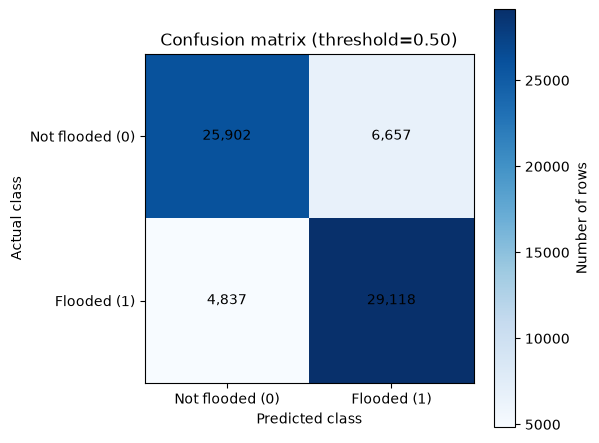

Saved figure to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\figures\roc_pr_curves.png


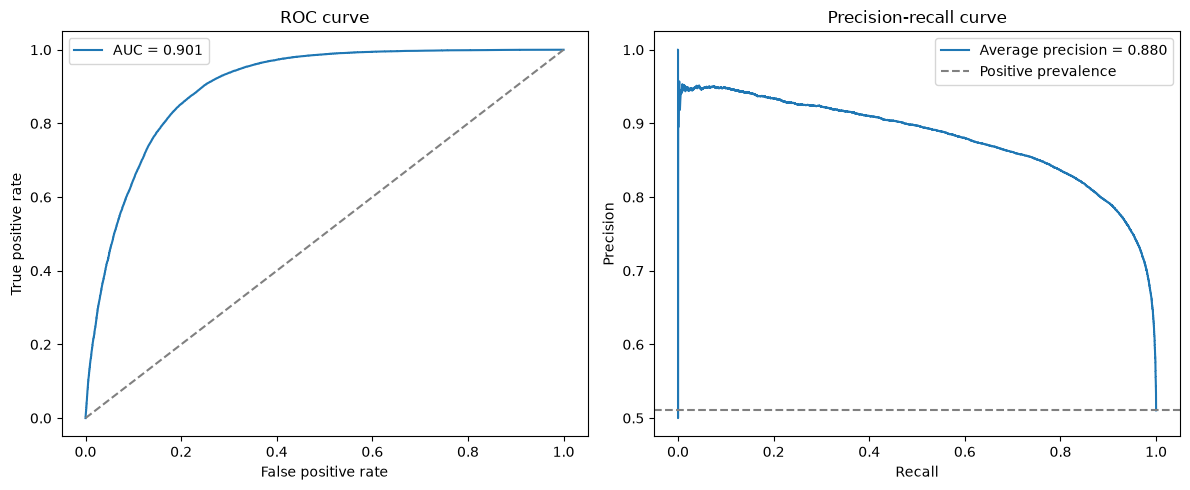

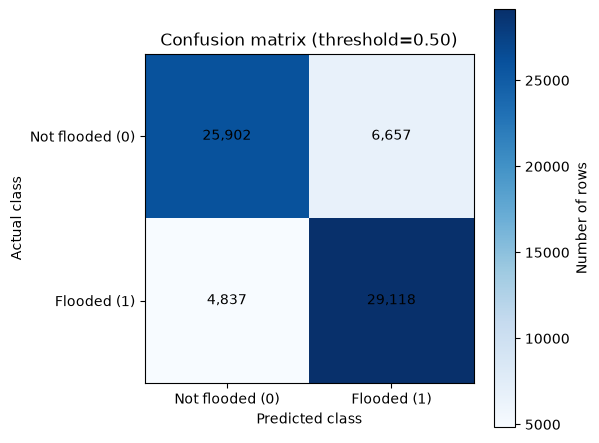

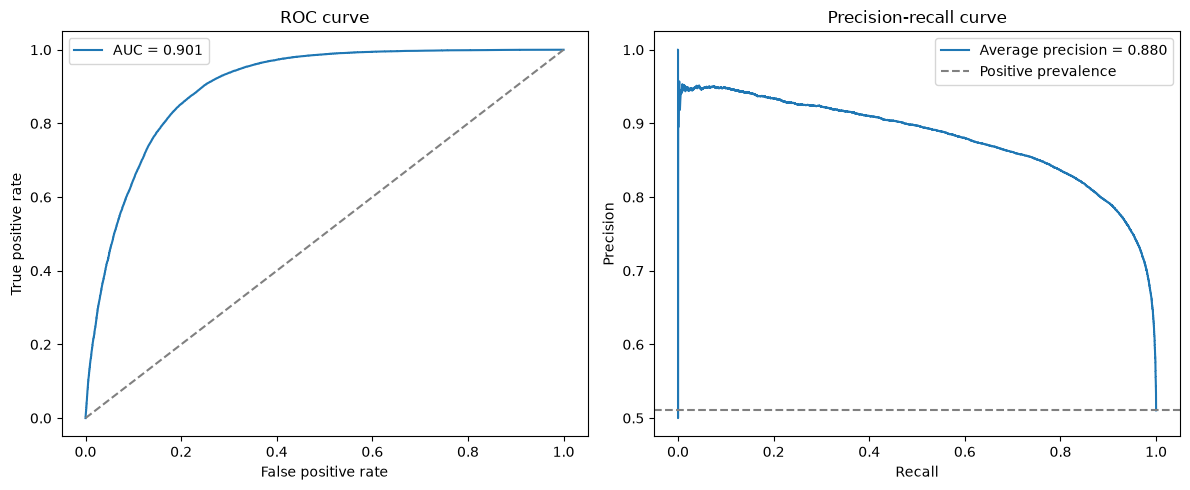

In [5]:
area_tree_results = comparison.loc[
    comparison["split"].eq("area_group")
    & comparison["model"].isin(tree_model_names)
].sort_values(["recall", "roc_auc"], ascending=False)
best_tree_model = area_tree_results.iloc[0]["model"]
best_tree_oof = evaluation_results[(best_tree_model, "area_group")][1]
print(f"Best tree by area-group recall: {best_tree_model}")
display(plot_confusion_matrix(best_tree_oof, threshold=0.5))
display(plot_roc_pr(best_tree_oof))

**My observations:** LightGBM was the best tree model by area-fold recall. At the 0.5 threshold it reached 0.857554 recall and 0.900738 ROC-AUC. These are cross-validation results, not final test results.

## 6. Random Forest feature importance

Fit Random Forest on all cleaned training rows and show its five largest built-in feature importances. This is a rough guide to what the fitted model uses, not a final explanation or a causal result. It is not evaluated on the held-out test data.

In [6]:
X, y = get_xy(df)
full_preprocessor = build_preprocessor()
X_transformed = full_preprocessor.fit_transform(X)
full_random_forest = MODEL_REGISTRY["random_forest"]()
full_random_forest.fit(X_transformed, y)
feature_names = full_preprocessor.get_feature_names_out()
top_feature_indices = np.argsort(full_random_forest.feature_importances_)[-5:][::-1]
top_features = pd.DataFrame(
    {
        "feature": feature_names[top_feature_indices],
        "importance": full_random_forest.feature_importances_[top_feature_indices],
    }
)
display(top_features)

,feature,importance
0,numeric__elevation_m,0.302940
1,numeric__slope_degrees,0.212401
2,numeric__rainfall_inches,0.183925
3,numeric__paved_pct,0.129483
4,numeric__distance_to_bayou_m,0.124007


**My observations:** Elevation, slope, and rainfall had the largest Random Forest importance values in this fit. These built-in scores are only a rough guide to model behavior; they do not prove that these features cause flooding.